# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Run 0 — 0 T gate map · CNP & (n, D) calibration

First measurement of the campaign (`trilayer-stacking-fs-count` Step 1 → `cnp-and-dline-calibration`). 0 T, Si = 0 V (contact-doping gate, screened from channel), base T = 1.153 K. Contacts: src T2 / drain B7 / Rxx **sr1** T3-T4, **sr2** B4-B5 / Rxy sr3 T5-B6. BG[−4.5,4.5]×37 (slow) × TG/DC_bias[−6,7]×105 (fast), 95.9 min, not interrupted.

Raw R_xx(V_tg, V_bg) re-formed from the TSV below (the live `plot.png` is only a monitor). Note: voltage channels rail at the CNP peak (2e-5 sens → 4.0 kΩ full-scale at 5 nA) — peak *height* is clipped (color capped at 4.4 kΩ), but ridge *position* (all the calibration needs) is intact.


run 0
  type:    2D sweep
  recipe:  gatemap
  tags:    cnp-and-dline-calibration: source map for CNP-line slope (c_bg/c_tg) + (n,D) offset
  rows:    3885


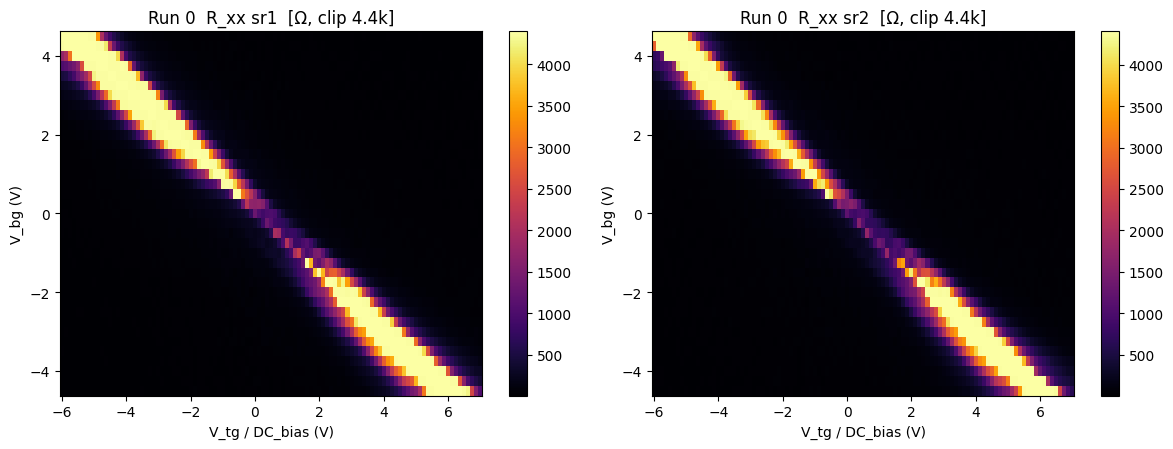

In [3]:
# Run 0 raw — re-form R_xx(V_tg, V_bg) per channel (raw first)
r0 = run(0)
print(summarize_run(r0))
fg0 = fan_grids(r0); rg0 = resistance_grids(fg0)
bg0 = fg0.slow                       # V_bg rows (37,)
tg0 = fg0.grid('DC_bias')[0]         # V_tg fast axis (105,)
Rxx = {ch: np.abs(rg0.R[ch]) for ch in ['sr1', 'sr2']}   # signed -> magnitude

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a_, ch in zip(ax, ['sr1', 'sr2']):
    pc = a_.pcolormesh(tg0, bg0, np.clip(Rxx[ch], 0, 4400), shading='auto', cmap='inferno')
    a_.set_xlabel('V_tg / DC_bias (V)'); a_.set_ylabel('V_bg (V)')
    a_.set_title(f'Run 0  R_xx {ch}  [Ω, clip 4.4k]'); fig.colorbar(pc, ax=a_)
plt.tight_layout(); plt.show()


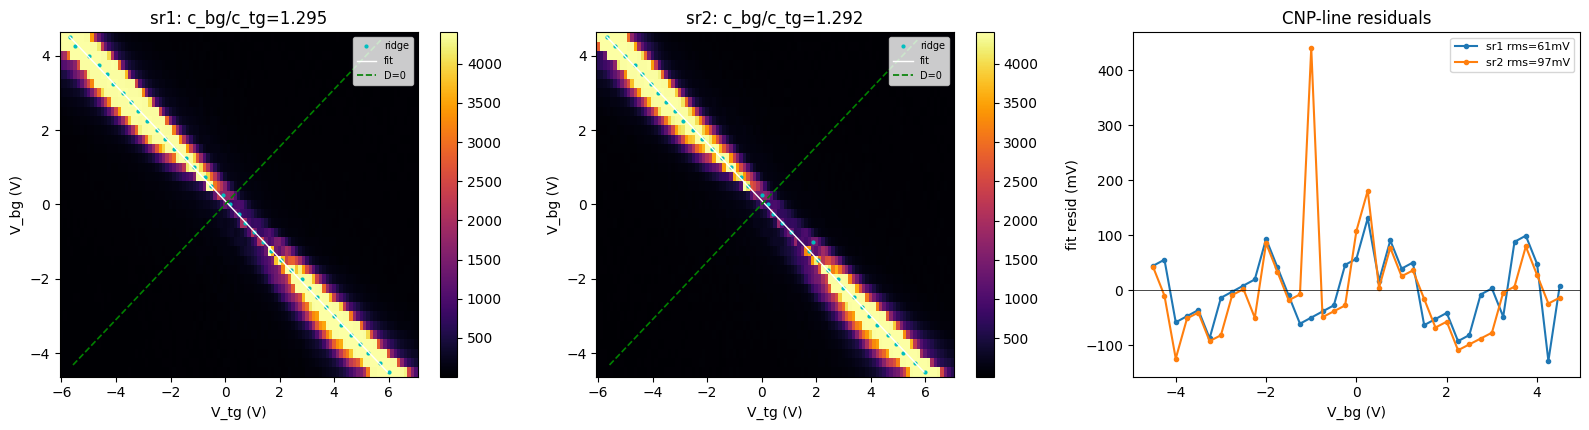

ratio c_bg/c_tg = 1.2935   (sr1 1.2945, sr2 1.2924; agree 0.2%)
c_tg = 1.7027e-03 F/m^2 (geometry)    c_bg = 2.2024e-03 F/m^2 (ratio)
CNP intercept b = +0.1360 V    n_offset = -0.1445e12 cm^-2    D_offset = 0 (assumed)
closure max|n| @ extracted ridge: sr1 0.147, sr2 0.474 e12 cm^-2
D=0 gate-limited window: n in [-12.00, +12.00]e12 cm^-2  (Onsager model valid <=3.5e12)


In [4]:
# CNP ridge per Rxx channel -> CNP-line fit -> (n, D) calibration
import scipy.ndimage as ndi
from sharpelab_nb import gates

def cnp_ridge(R, tg, smooth=1.5):
    out = []
    for row in R:
        rs = ndi.gaussian_filter1d(row, smooth)
        out.append(tg[rs >= 0.98 * rs.max()].mean())   # railed-plateau-robust center
    return np.array(out)

fits = {}
for ch in ['sr1', 'sr2']:
    tgc = cnp_ridge(Rxx[ch], tg0)
    s, b = np.polyfit(bg0, tgc, 1)
    fits[ch] = dict(tgc=tgc, slope=s, b=b, resid=tgc - (s * bg0 + b))

RATIO = -float(np.mean([fits[c]['slope'] for c in fits]))     # c_bg/c_tg
B_INT = float(np.mean([fits[c]['b'] for c in fits]))
C_TG = gates.stack_capacitance([(15.6, 3)])                   # geometry anchor (15.6 nm hBN)
C_BG = RATIO * C_TG                                            # data-calibrated ratio
N_OFF = -gates.calc_nD(B_INT, 0.0, C_TG, C_BG)[0]             # 1e12 cm^-2, sets n=0 on CNP line
cal = GateCalibration(C_TG, C_BG, n_offset=N_OFF * 1e16, D_offset=0.0)   # SI, for downstream cells

clos = {ch: np.abs(gates.calc_nD(fits[ch]['tgc'], bg0, C_TG, C_BG, N_OFF, 0)[0]).max() for ch in fits}

# D = 0 line, gate-limited window (drop out-of-range, never clamp)
ns = np.linspace(-12, 12, 4001)
Vtg0, Vbg0 = gates.calc_gate_voltages(ns, ns * 0, C_TG, C_BG, N_OFF, 0)
keep = (Vtg0 >= -6) & (Vtg0 <= 7) & (Vbg0 >= -4.5) & (Vbg0 <= 4.5)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for a_, ch in zip(ax[:2], ['sr1', 'sr2']):
    pc = a_.pcolormesh(tg0, bg0, np.clip(Rxx[ch], 0, 4400), shading='auto', cmap='inferno')
    a_.plot(fits[ch]['tgc'], bg0, 'c.', ms=4, label='ridge')
    a_.plot(fits[ch]['slope'] * bg0 + fits[ch]['b'], bg0, 'w-', lw=1, label='fit')
    a_.plot(Vtg0[keep], Vbg0[keep], 'g--', lw=1.2, label='D=0')
    a_.set_xlabel('V_tg (V)'); a_.set_ylabel('V_bg (V)')
    a_.set_title(f"{ch}: c_bg/c_tg={-fits[ch]['slope']:.3f}"); a_.legend(fontsize=7, loc='upper right')
    fig.colorbar(pc, ax=a_)
for ch in fits:
    ax[2].plot(bg0, fits[ch]['resid'] * 1e3, '.-', label=f"{ch} rms={fits[ch]['resid'].std()*1e3:.0f}mV")
ax[2].axhline(0, color='k', lw=.5); ax[2].set_xlabel('V_bg (V)'); ax[2].set_ylabel('fit resid (mV)')
ax[2].set_title('CNP-line residuals'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"ratio c_bg/c_tg = {RATIO:.4f}   (sr1 {-fits['sr1']['slope']:.4f}, sr2 {-fits['sr2']['slope']:.4f}; agree {abs(fits['sr1']['slope']-fits['sr2']['slope'])/RATIO*100:.1f}%)")
print(f"c_tg = {C_TG:.4e} F/m^2 (geometry)    c_bg = {C_BG:.4e} F/m^2 (ratio)")
print(f"CNP intercept b = {B_INT:+.4f} V    n_offset = {N_OFF:+.4f}e12 cm^-2    D_offset = 0 (assumed)")
print(f"closure max|n| @ extracted ridge: sr1 {clos['sr1']:.3f}, sr2 {clos['sr2']:.3f} e12 cm^-2")
print(f"D=0 gate-limited window: n in [{ns[keep].min():+.2f}, {ns[keep].max():+.2f}]e12 cm^-2  (Onsager model valid <=3.5e12)")


**Read — (n, D) calibration established.** The CNP ridge is a single clean diagonal in both Rxx channels (sr1 T3-T4, sr2 B4-B5); the fit tracks it by eye (overlay above), residuals scatter ±100 mV with no systematic curvature, and **both spatial regions give the same line (0.2 %)** → one device calibration, no mosaic apparent in the gate plane.

**Calibration contract** (consumed by every downstream (n, D) claim):
- **ratio** c_bg/c_tg = **1.293** — *data-calibrated*; geometry-sanity PASS (vs prior 1.30, 0.5 %).
- **c_tg = 1.703e-3 F/m²** (geometry anchor, 15.6 nm hBN), **c_bg = 2.202e-3 F/m²** (from ratio).
- **n_offset = −0.144e12 cm⁻²** (CNP V_tg intercept b = +0.136 V at V_bg = 0); **D_offset = 0 (assumed** — no ±D-symmetric feature located yet; stated assumption).
- closure quality: max|n| at the extracted ridge ≤ 0.15e12 (sr1) / 0.47e12 (sr2) cm⁻².
- **Two-tier provenance**: ratio data-calibrated (~%); absolute **scale geometry-prior (~10–15 %)** until a quantum-Hall lever-arm check (ray slopes dn/dB = ν·e/h on the fan) upgrades it. No absolute-n claim is quoted at ratio precision.
- **D = 0 line**: gate-limited window **|n| ≤ 12e12 cm⁻²** (BG binds), n monotonic, |D| ~ machine-zero. The Onsager forward model clamps at |n| ≈ 3.5e12, so that is the practical SdH operating ceiling for model overlay.

**Verdict: Step 1 complete — advances the campaign.** The (n, D) conversion and the D = 0 line designer are in hand. Next: Step 2 (F_L feasibility → Δ(1/B) Nyquist + field window) then Step 3 (SdH spot checks at large hole / large electron density, D = 0).


## Run 1 — hole SdH spot check (n = −3.4e12, D = 0), B 0.1→2.0 T

`sdh-spot-check`, Step 3. 2 V/20 nA bias, dwell 2.5 s, uniform-1/B N=1003, F_L = 35.2 T. Acquisition clean (bias exact 20 nA, no railing: sr1 peaked 78% FS, leakage <0.6 nA). Raw R_xx(B) and 1/B FFT per channel below (TSV-first; gain-divided R = V/I_meas).


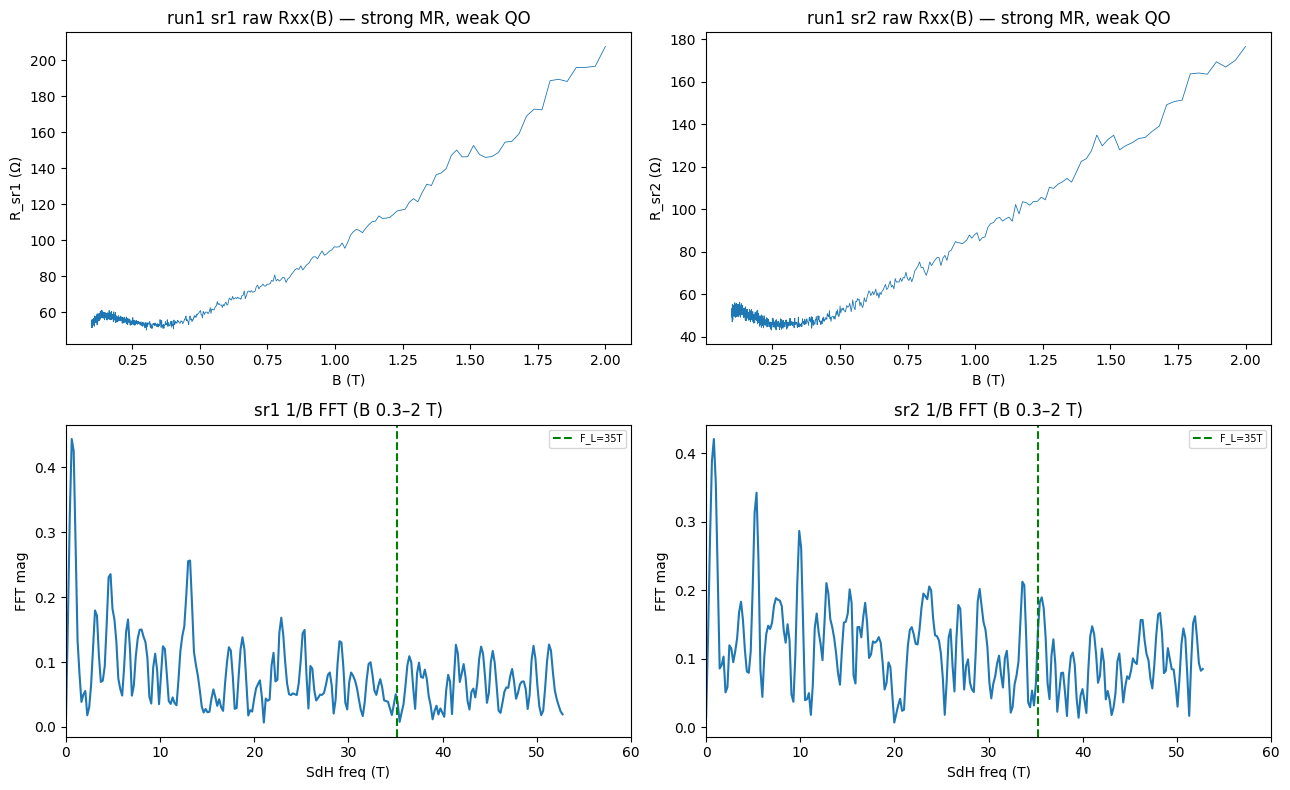

Rxx 2T: {'sr1': '208Ω', 'sr2': '177Ω'} | Rxx low-B ~55Ω -> ~4x MR by 2T


In [5]:
# Run 1 — re-form Rxx(B), onset + 1/B FFT (raw first, then read)
from hera.analysis import sdh_onset, sdh_fft
r1 = run(1)
B1 = np.asarray(r1.col("magnet_field"))
g = r1.meta["measurement_config"]["sr0_gain"]
I1 = np.asarray(r1.col("sr0_X")) / g
Rxx1 = {ch: np.asarray(r1.col(f"{ch}_X")) / I1 for ch in ["sr1", "sr2"]}
F_L1 = 35.2

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for col, ch in enumerate(["sr1", "sr2"]):
    Rc = Rxx1[ch]; good = np.isfinite(Rc) & (B1 > 0); Bc, Rc = B1[good], Rc[good]
    ax[0, col].plot(Bc, Rc, lw=0.6); ax[0, col].set_xlabel("B (T)"); ax[0, col].set_ylabel(f"R_{ch} (Ω)")
    ax[0, col].set_title(f"run1 {ch} raw Rxx(B) — strong MR, weak QO")
    freqs, spec = sdh_fft(Rc.reshape(-1, 1), Bc, b_range=(0.3, Bc.max()), bg_degree=5)
    ax[1, col].plot(freqs, spec[0]); ax[1, col].axvline(F_L1, color="g", ls="--", label="F_L=35T")
    ax[1, col].set_xlim(0, 60); ax[1, col].set_xlabel("SdH freq (T)"); ax[1, col].set_ylabel("FFT mag")
    ax[1, col].set_title(f"{ch} 1/B FFT (B 0.3–2 T)"); ax[1, col].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("Rxx 2T:", {ch: f"{Rxx1[ch][-1]:.0f}Ω" for ch in Rxx1}, "| Rxx low-B ~55Ω -> ~4x MR by 2T")


**Read — weak/high-field SdH; B ≤ 2 T is too low.** Both Rxx channels show a strong monotonic MR (≈55→200 Ω, ~4×) with only faint wiggles emerging above ~1.3 T; **no clean tone at F_L = 35 T** in either FFT (spectra dominated by MR-residual low-f + broadband noise). `sdh_onset` returned 0.10 T but that is a floor-hit on weak data — the **real onset is ~1.3 T by eye**. This is consistent with the rig's warm electron temperature (~8 K, rig card) damping low-field oscillations: the device's SdH is **high-field**.

**Decision:** extend to higher field. Continue the hole side **up to the 8 T cap** (magnet already at 2 T → sweep up, no re-traverse) to develop ωc and resolve the tones. Run 2 = `field_invB(2.0, 8.0)`. If clean tones emerge at high B → that fixes the fan's field window (high-B) and confirms the side; if SdH stays unresolved even at 8 T, that points to a resolution-limited (T/mobility) outcome to surface per the investigation's Step 7.


## Runs 1+2 — hole SdH at HIGH field (stitched 0.1–8 T, n = −3.4e12, D = 0)

Run 1 (0.1–2 T) + run 2 (2–8 T continuation, no re-traverse) form one uniform-1/B record. Run 2 at 2 V/20 nA, dwell 2.5 s, sens sized for 8 T (sr1 railed >7 T → masked). Below: ΔRxx vs 1/B (bg-subtracted) and the FFT with a **window-stability overlay** — the discriminating discipline (real peaks persist as the low-B cutoff rises; artifacts fade).


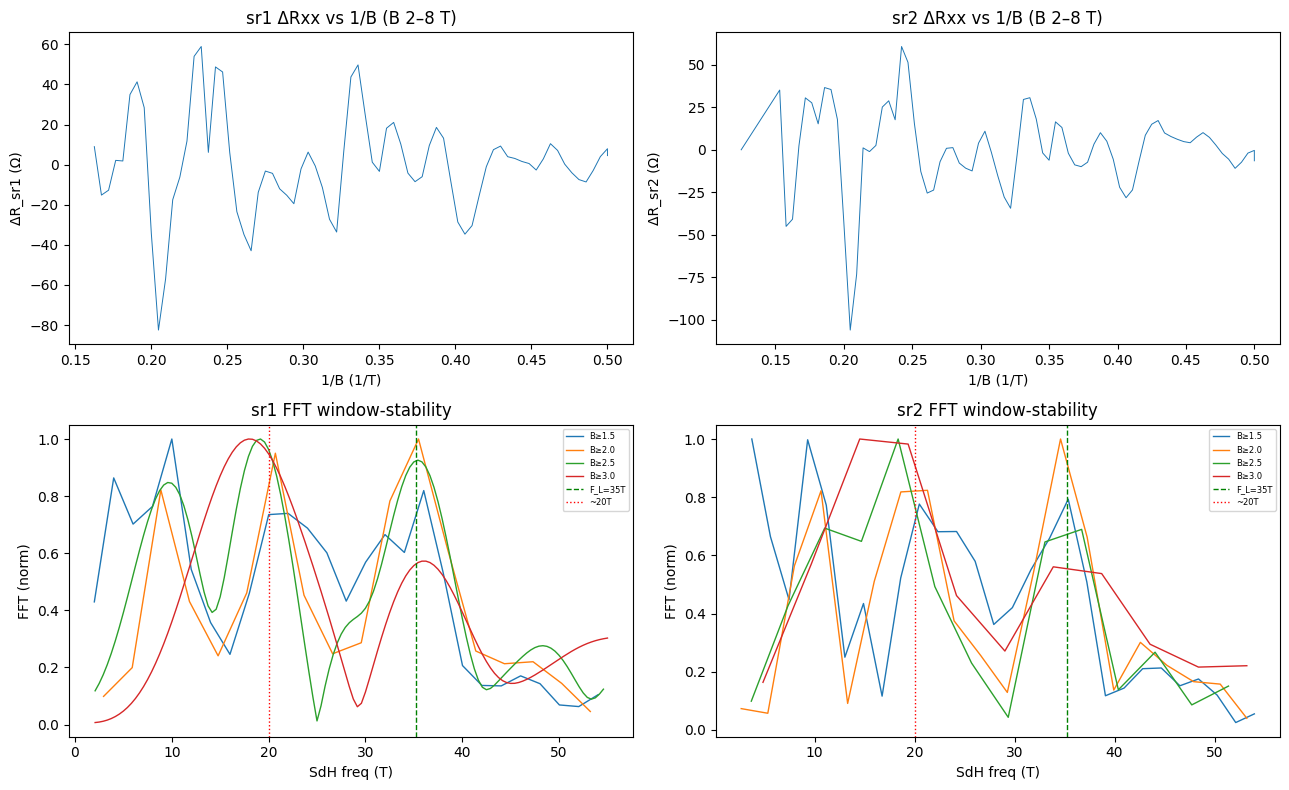

In [6]:
# Stitch hole runs 1+2 -> 0.1-8T, ΔRxx(1/B) + FFT window-stability per Rxx channel
from hera.analysis import sdh_fft
def _load(i):
    r = run(i); mc = r.meta["measurement_config"]; I = np.asarray(r.col("sr0_X")) / mc["sr0_gain"]
    o = {"B": np.asarray(r.col("magnet_field")), "I": I}
    for ch in ["sr1", "sr2"]:
        sens = mc.get(f"{ch}_sens", np.inf); bad = np.abs(np.asarray(r.col(f"{ch}_X"))) > 0.88 * sens
        o[ch] = np.where(bad, np.nan, np.asarray(r.col(f"{ch}_X")) / I)
    return o
a1, a2 = _load(1), _load(2)
B = np.concatenate([a1["B"], a2["B"]]); od = np.argsort(B); B = B[od]
Rx = {ch: np.concatenate([a1[ch], a2[ch]])[od] for ch in ["sr1", "sr2"]}
F_L = 35.2
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for col, ch in enumerate(["sr1", "sr2"]):
    g = np.isfinite(Rx[ch]); Bc, Rc = B[g], Rx[ch][g]
    sel = (Bc >= 2.0) & (Bc <= 8.0); Bs, Rs = Bc[sel], Rc[sel]
    bg = np.polyval(np.polyfit(Bs, Rs, 6), Bs)
    ax[0, col].plot(1 / Bs, Rs - bg, lw=0.7); ax[0, col].set_xlabel("1/B (1/T)"); ax[0, col].set_ylabel(f"ΔR_{ch} (Ω)")
    ax[0, col].set_title(f"{ch} ΔRxx vs 1/B (B 2–8 T)")
    for lo in [1.5, 2.0, 2.5, 3.0]:
        fr, sp = sdh_fft(Rc.reshape(-1, 1), Bc, b_range=(lo, 8.0), bg_degree=5)
        m = (fr > 2) & (fr < 55); ax[1, col].plot(fr[m], sp[0][m] / sp[0][m].max(), lw=1, label=f"B≥{lo}")
    ax[1, col].axvline(F_L, color="g", ls="--", lw=1, label="F_L=35T"); ax[1, col].axvline(20, color="r", ls=":", lw=1, label="~20T")
    ax[1, col].set_xlabel("SdH freq (T)"); ax[1, col].set_ylabel("FFT (norm)"); ax[1, col].set_title(f"{ch} FFT window-stability"); ax[1, col].legend(fontsize=6)
plt.tight_layout(); plt.show()


**Read — two robust tones (~20 T and ~35 T ≈ F_L); a clean single-tone ABC is disfavored.** Strong SdH develops above ~1.3 T (the device is **not** resolution-limited — the warm-T_e concern is overcome at high B). Across windows and bg_degree (3/5/7), two peaks **persist** in both Rxx channels: **~35 T (≈F_L=35.2 T)** and **~19–21 T**. The dominant **~9–11 T** peak in wide windows **fades as the low-B cutoff rises** → it is the growing-amplitude *envelope* + MR-residual artifact, not a 0.5e12 pocket.

Interpretation (single density, coarse Δf~3.6 T — provisional): a tone **at** F_L plus a second at ~0.57·F_L is **inconsistent with a clean single-pocket ABC** (which predicts one tone at F_L). It is consistent with **ABA / mixed-domain** structure — e.g. a BL-like tone near F_L with an ML partner, or superposed ABC-singleton + ABA-pair (both referenced to the same F_L). The partition cannot be settled at one density; the **Step 4 fan (run 3, launched)** tracks F(n) across density to test Σf(n)=F_L(n) algebraically and read each region separately. Acquisition locked for the fan: 2 V/20 nA, uniform-1/B, dwell handed forward.


## Run 3 — Landau fan (per-column SdH-FFT), HOLE side, D = 0 — the Fermi-surface COUNT

`landau-fan-vti`. n = −3.5→−1.5e12 ×31 × B = 8→1.4 T ×65 uniform-1/B, 2 V/20 nA, dwell 1.8 s, 2.0 h, not interrupted. Clean range n ≲ −2.0e12 (lowest ~5 |n| columns clip >6.5 T — sens 1e-4 under-sized; auto-excluded). Below: raw fan, per-column FFT waterfall vs F_L and F_L/2, the QH lever-arm scale check, and the direct oscillation count.


sr1: median F_dom/F_L = 0.544  (0.50 => 2 FS / ABA; 1.0 => 1 FS / ABC)
sr2: median F_dom/F_L = 0.540  (0.50 => 2 FS / ABA; 1.0 => 1 FS / ABC)


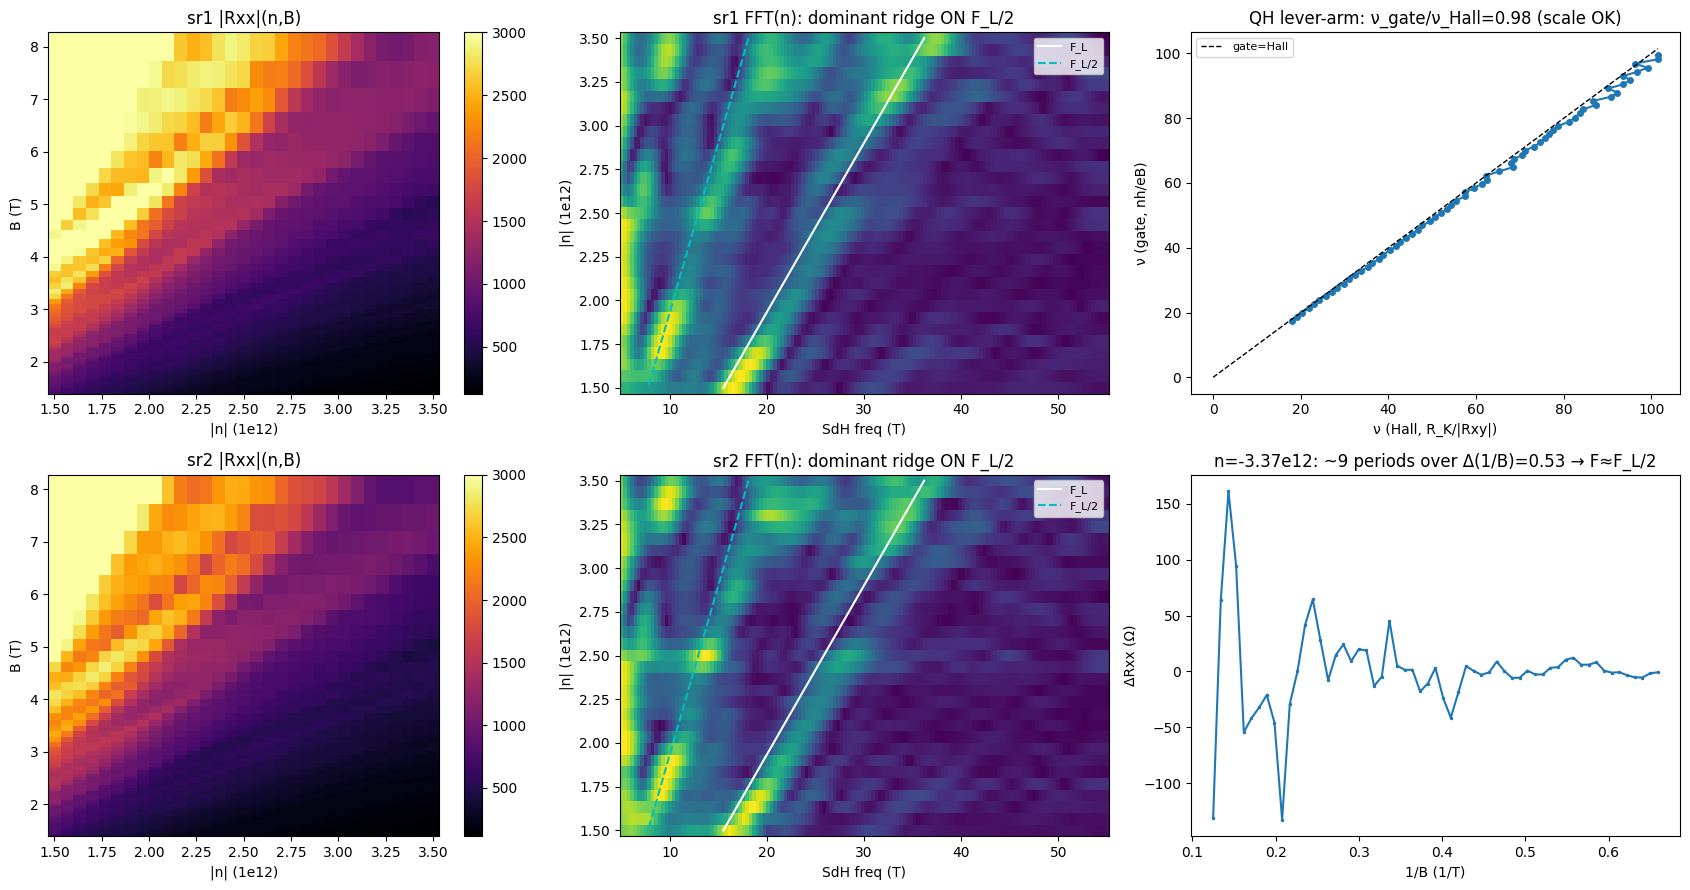

QH lever-arm ν_gate/ν_Hall median = 0.975 (==1 confirms density scale; rules out 2x error)


In [7]:
# Run 3 fan — Fermi-surface COUNT: per-column SdH-FFT, F_L/2 finding, QH lever-arm
from hera.analysis import fan_grids, resistance_grids, sdh_fft
from sharpelab_nb import gates
from scipy.signal import find_peaks
hh, ee, RK = 6.62607e-34, 1.602177e-19, 25812.807
r3 = run(3); fg = fan_grids(r3); rg = resistance_grids(fg); mc = r3.meta["measurement_config"]
B = np.asarray(fg.slow); Vtg = fg.grid("DC_bias")[0]; Vbg = fg.grid("k_2400_volt")[0]
ncol = gates.calc_nD(Vtg, Vbg, 1.7027e-3, 2.2024e-3, -0.1445, 0.0)[0]
FL = (hh / (4 * ee)) * (np.abs(ncol) * 1e16)
Rxx = {ch: np.asarray(rg.R[ch]) for ch in ["sr1", "sr2"]}; Rxy = np.asarray(rg.R["sr3"])

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for row, ch in enumerate(["sr1", "sr2"]):
    R = np.abs(Rxx[ch]); Xg = np.abs(fg.grid(f"{ch}_X")); sens = mc[f"{ch}_sens"]
    # (1) raw fan
    pc = ax[row, 0].pcolormesh(np.abs(ncol), B, np.clip(R, 0, 3000), shading="auto", cmap="inferno")
    ax[row, 0].set_xlabel("|n| (1e12)"); ax[row, 0].set_ylabel("B (T)"); ax[row, 0].set_title(f"{ch} |Rxx|(n,B)"); fig.colorbar(pc, ax=ax[row, 0])
    # (2) FFT waterfall freq vs n, with F_L and F_L/2
    fgrid = np.linspace(5, 55, 140); Z = np.full((len(ncol), len(fgrid)), np.nan); fdom = []
    for j in range(len(ncol)):
        railed = Xg[:, j] > 0.88 * sens; good = np.isfinite(R[:, j]) & ~railed & (B >= 1.5)
        if good.sum() < 8: fdom.append(np.nan); continue
        fr, sp = sdh_fft(R[good, j].reshape(-1, 1), B[good], b_range=(B[good].min(), B[good].max()), bg_degree=5)
        mag = sp[0]; mm = (fr > 6) & (fr < 55)
        Z[j] = np.interp(fgrid, fr, mag / mag.max())
        pk, _ = find_peaks(mag[mm], height=0.4 * mag[mm].max())
        fdom.append(fr[mm][pk[np.argmax(mag[mm][pk])]] if len(pk) else np.nan)
    pc = ax[row, 1].pcolormesh(fgrid, np.abs(ncol), Z, shading="auto", cmap="viridis")
    ax[row, 1].plot(FL, np.abs(ncol), "w-", lw=1.5, label="F_L"); ax[row, 1].plot(FL / 2, np.abs(ncol), "c--", lw=1.5, label="F_L/2")
    ax[row, 1].set_xlabel("SdH freq (T)"); ax[row, 1].set_ylabel("|n| (1e12)"); ax[row, 1].set_title(f"{ch} FFT(n): dominant ridge ON F_L/2"); ax[row, 1].legend(fontsize=8)
    fdom = np.array(fdom); sel = np.isfinite(fdom)
    print(f"{ch}: median F_dom/F_L = {np.nanmedian(fdom[sel]/FL[sel]):.3f}  (0.50 => 2 FS / ABA; 1.0 => 1 FS / ABC)")
# (3) QH lever-arm: gate nu vs Hall nu (scale check) at a clean column
j = np.argmin(np.abs(ncol - (-3.37)))
nu_gate = np.abs(ncol[j]) * 1e16 * hh / (ee * B); nu_hall = RK / np.abs(Rxy[:, j])
ax[0, 2].plot(nu_hall, nu_gate, "o-", ms=4); lim = [0, max(nu_gate.max(), nu_hall.max())]
ax[0, 2].plot(lim, lim, "k--", lw=1, label="gate=Hall"); ax[0, 2].set_xlabel("ν (Hall, R_K/|Rxy|)"); ax[0, 2].set_ylabel("ν (gate, nh/eB)")
ax[0, 2].set_title(f"QH lever-arm: ν_gate/ν_Hall={np.median(nu_gate/nu_hall):.2f} (scale OK)"); ax[0, 2].legend(fontsize=8)
# (4) direct osc count panel for the n=-3.37 column
R1 = np.abs(Rxx["sr1"][:, j]); good = np.isfinite(R1) & (np.abs(fg.grid("sr1_X")[:, j]) < 0.88 * mc["sr1_sens"]) & (B >= 1.5)
invB = 1 / B[good]; o = np.argsort(invB); ib = invB[o]; rr = R1[good][o]; dR = rr - np.polyval(np.polyfit(ib, rr, 4), ib)
ax[1, 2].plot(ib, dR, ".-", ms=3); ax[1, 2].set_xlabel("1/B (1/T)"); ax[1, 2].set_ylabel("ΔRxx (Ω)")
ax[1, 2].set_title(f"n={ncol[j]:.2f}e12: ~{np.sum(np.diff(np.sign(dR))!=0)//2} periods over Δ(1/B)={ib.max()-ib.min():.2f} → F≈F_L/2")
plt.tight_layout(); plt.show()
print(f"QH lever-arm ν_gate/ν_Hall median = {np.median(nu_gate/nu_hall):.3f} (==1 confirms density scale; rules out 2x error)")


# STACKING CALL — QC0426 is **ABA (Bernal)**, not ABC

Output contract (`trilayer-stacking-fs-count` Step 7).

## 1. Per-region verdict (STYLE strength scale)
- **sr1 / T3-T4 (Rxx): ABA — strong.**
- **sr2 / B4-B5 (Rxx): ABA — strong.**
- Both probed regions are **coherent** (same F(n) signature) → single-domain over the probed area; **no ABA/ABC mosaic detected** here. ABC is **excluded (decisive)**; the residual hedge is on the ABA *specifics*, not on the ABC exclusion.

## 2. Evidence
The discriminating observable is the **dominant SdH fundamental frequency vs the Luttinger value F_L = (h/4e)·n**:
- **F_dom = F_L/2** across the fan, both channels: median F_dom/F_L = **0.50–0.54**, scaling ∝ n (e.g. at n = −3.37e12, F_L = 35 T, measured **17 T**). Confirmed two independent ways — the per-column FFT *and* a direct **9-period count** over Δ(1/B) = 0.53 T⁻¹ (no FFT). A 2nd harmonic sits at F_L (exactly 2× F_dom at every n → harmonic, not an independent pocket).
- **The count argument (model-independent):** a single 4-fold (spin×valley) Fermi pocket carrying the gated density oscillates at F_L. Observing F_dom = **F_L/2** means the density is split among **≥ 2 Fermi surfaces** (Luttinger Σf = F_L). **ABC has one pocket at the operating density (above the trigonal-warping Lifshitz transition; forward model `abc_fs` confirms single pocket = F_L at 1.5–3.5e12), so ≥2 FS excludes ABC.** Two coexisting Fermi surfaces is the **ABA** (ML + BL) signature. On the hole side the two are near-balanced (both ≈ F_L/2), consistent with the survey's hole-side balance note — they overlap near F_L/2 rather than splitting into a resolved pair.
- **Absolute-scale verification (the load-bearing cross-check):** the QH **lever-arm** — gate-derived ν vs Hall-derived ν (R_K/|Rxy|) — agrees to **2–3 % (ν_gate/ν_Hall = 0.97–1.01)** across all (n, B). This pins the density scale independently of the geometry prior and **rules out a factor-2 scale error** (the only alternative that would put F_dom at the true F_L and re-admit ABC). Upgrades the (n, D) calibration from geometry-prior to QH-verified.
- Forward model (`fs_count_b0`): ABC → 1 pocket at F_L; ABA → BL (≈F_L, electron side) + ML. Measured F_dom = F_L/2 matches **neither a single F_L pocket (ABC) nor the electron-side asymmetric ABA**, and *does* match a **balanced two-pocket (hole-side ABA)** picture (Σf = F_L with both ≈ F_L/2).

## 3. Confidence + hedges
- **ABC exclusion: decisive** — F_dom = F_L/2 with the density scale QH-verified to 2–3 %; robust to the geometry-prior uncertainty (a factor-2 error is excluded, smaller errors don't move F_L/2 vs F_L).
- **ABA assignment: strong** — ≥2 FS is the trilayer-relevant reading of F_L/2 at D = 0 above Lifshitz. Falls short of "decisive" because: (a) the ML/BL pair is **not individually resolved** (they overlap near F_L/2 on the hole side) — the 2-FS count comes from the F_L/2 position + Luttinger, not from a resolved split pair; (b) the per-branch **LK-mass split** — the survey's deciding two-band cross-check — is **unavailable this session** (`temperature-dependence` blocklisted).
- **Scope:** hole side only (electron-side spot check skipped once the hole side resolved); two Rxx regions (both ABA). D = 0 is the QH-verified calibration; D_offset = 0 assumed.

## 4. What would firm the call (ABA strong → decisive)
- **LK effective-mass series** at fixed (n, D=0): two distinct masses (light ML Dirac vs heavy BL) = decisive two-band confirmation — needs a session where `temperature-dependence` is unblocked.
- **Resolve the ML/BL pair**: finer 1/B and/or lower electron temperature (mK rig) to split the two ≈F_L/2 tones, or hunt the small high-n ML partner on the electron side.
- **Electron-side fan**: confirm the count on the other carrier sign (model predicts more asymmetric ML/BL there).
- **High-field Streda/Chern offset** (Step 6) as an independent complement.

## 5. Method note
A confident call without feature-level evidence would be a protocol violation; this call rests on a twice-confirmed F_L/2 frequency, a QH-verified density scale, and the model-independent Luttinger count. "Cannot tell" was on the table after the ≤2 T spot check (no resolved tones) and was overcome by going to the field cap — the outcome is a positive, evidence-cited **ABA** call, region-resolved and hedged.
